## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print(os.listdir(path))

['amz_uk_price_prediction_dataset.csv']


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
import sys
print(sys.executable)

C:\Users\catar\anaconda3\python.exe


In [4]:
df = pd.read_csv(os.path.join(path, "amz_uk_price_prediction_dataset.csv"))
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [5]:
# Generating a crosstab for 'isBestSeller'
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head(10)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


In [6]:
bestseller_rate = df.groupby("category")["isBestSeller"].mean().sort_values(ascending=False)
bestseller_rate.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: isBestSeller, dtype: float64

In [7]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab)

chi2_statistic, chi2_p_value, expected_freq

(np.float64(36540.20270061387),
 np.float64(0.0),
 array([[2.47190130e+02, 8.09870149e-01],
        [4.05371878e+03, 1.32812173e+01],
        [2.49183599e+02, 8.16401360e-01],
        [1.69145827e+03, 5.54173243e+00],
        [2.53170536e+02, 8.29463782e-01],
        [8.50214439e+03, 2.78556144e+01],
        [1.06650580e+02, 3.49419782e-01],
        [2.57157474e+02, 8.42526204e-01],
        [9.51781673e+03, 3.11832664e+01],
        [1.50008526e+04, 4.91473619e+01],
        [9.32544700e+03, 3.05530045e+01],
        [2.38219520e+02, 7.80479700e-01],
        [3.22941944e+03, 1.05805616e+01],
        [9.44704859e+03, 3.09514084e+01],
        [6.68808779e+03, 2.19122125e+01],
        [5.26275760e+02, 1.72423967e+00],
        [1.90296531e+04, 6.23469391e+01],
        [2.77191835e+03, 9.08164873e+00],
        [2.53170536e+02, 8.29463782e-01],
        [4.04674164e+02, 1.32583581e+00],
        [1.92489346e+04, 6.30653723e+01],
        [3.10482764e+03, 1.01723609e+01],
        [2.04330551e+02, 6

In [8]:
pd.DataFrame(expected_freq, columns=crosstab.columns, index=crosstab.index).round(0)

isBestSeller,False,True
category,,
3D Printers,247.0,1.0
3D Printing & Scanning,4054.0,13.0
Abrasive & Finishing Products,249.0,1.0
Action Cameras,1691.0,6.0
Adapters,253.0,1.0
...,...,...
Wind Instruments,249.0,1.0
Window Treatments,238.0,1.0
Women,17714.0,58.0


In [9]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab' using the "cramer" method
association(crosstab, method="cramer")

0.1222829439760564

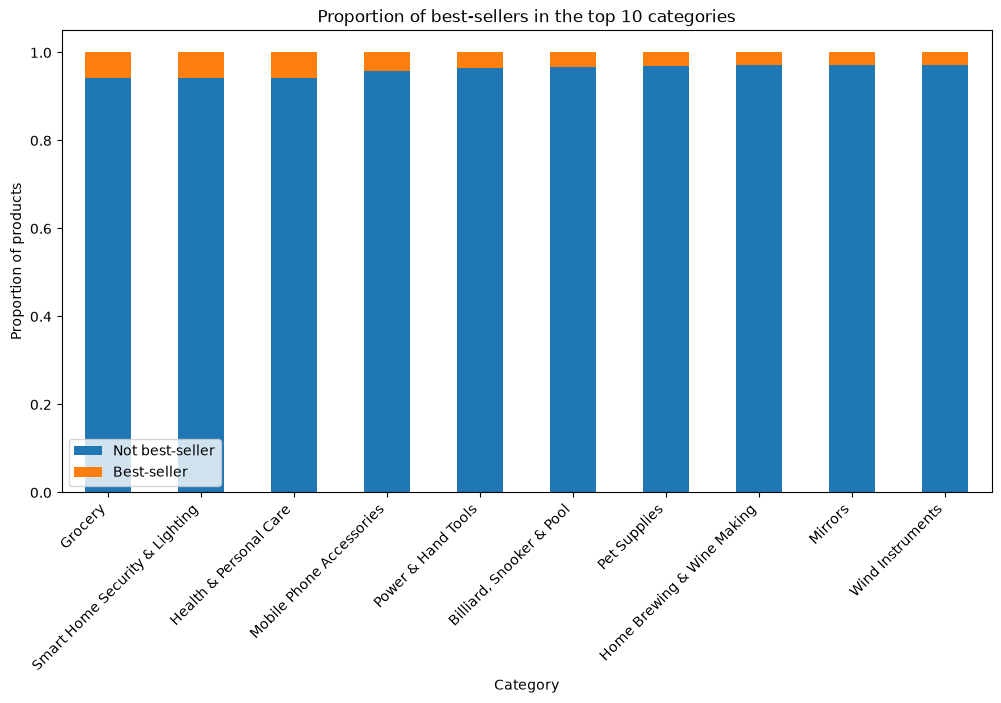

In [10]:
# Top 10 categories by best-seller 
top10 = bestseller_rate.head(10).index

# Crosstab as proportions
crosstab_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")

# Keep only the top 10 categories and plot them
crosstab_prop.loc[top10].plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Proportion of best-sellers in the top 10 categories")
plt.xlabel("Category")
plt.ylabel("Proportion of products")
plt.legend(["Not best-seller", "Best-seller"])
plt.xticks(rotation=45, ha="right")
plt.show()

In all categories best-sellers are a small minority, but some categories have a much higher share than others, such as "Grocery"
The p-value is close to 0 (p < 0.001), so we reject the idea that best-seller status and category are independent. In other words, best-seller status depends on the category: some categories have more best-sellers than you’d expect by chance. However, Cramér’s V (0.122) shows this association is weak. With 2.4 million products, even small differences between categories become statistically significant.


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [14]:
#Violin Plots
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[(df["price"] >= Q1 - 1.5 * IQR) & (df["price"] <= Q3 + 1.5 * IQR)]

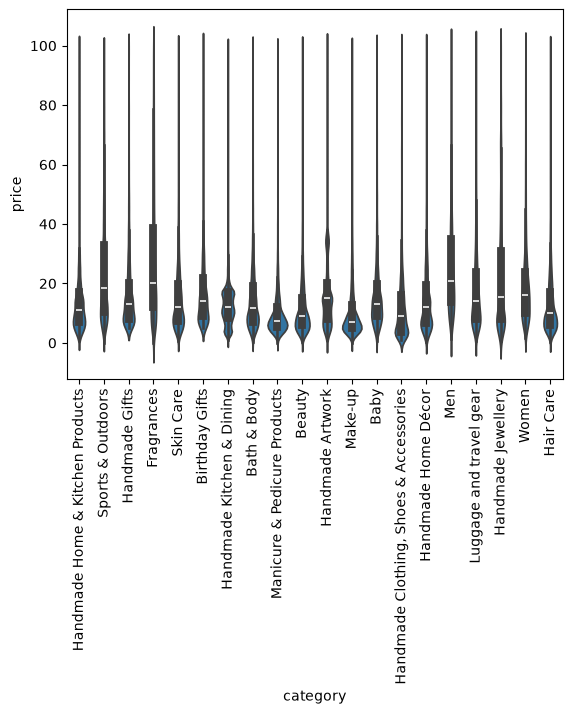

In [15]:
top20 = df_clean["category"].value_counts().head(20).index

sns.violinplot(data=df_clean[df_clean["category"].isin(top20)], x="category", y="price")
plt.xticks(rotation=90)
plt.show()

In [16]:
df_clean.groupby("category")["price"].median().sort_values(ascending=False).head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

'Desktop PCs' is the category with the highest median price.

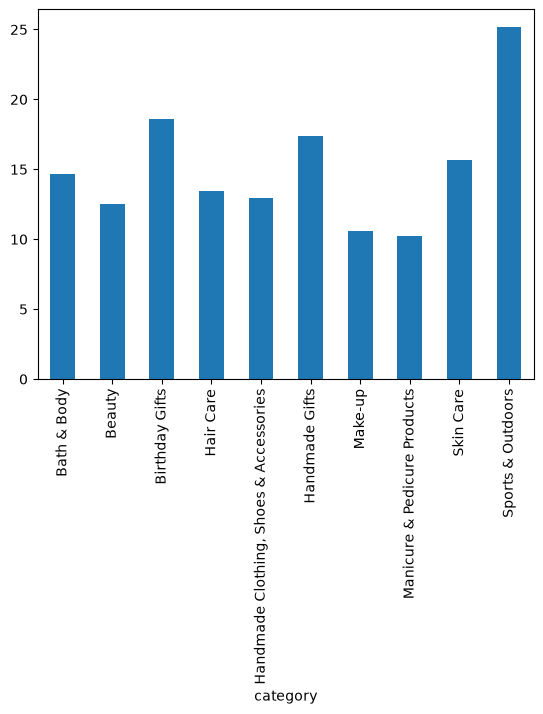

In [17]:
# Bar Charts
top10 = df_clean["category"].value_counts().head(10).index

df_clean[df_clean["category"].isin(top10)].groupby("category")["price"].mean().plot(kind="bar")
plt.show()

In [18]:
df_clean.groupby("category")["price"].mean().sort_values(ascending=False).head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

'Motherboards' is thes product category that commands the highest average price.

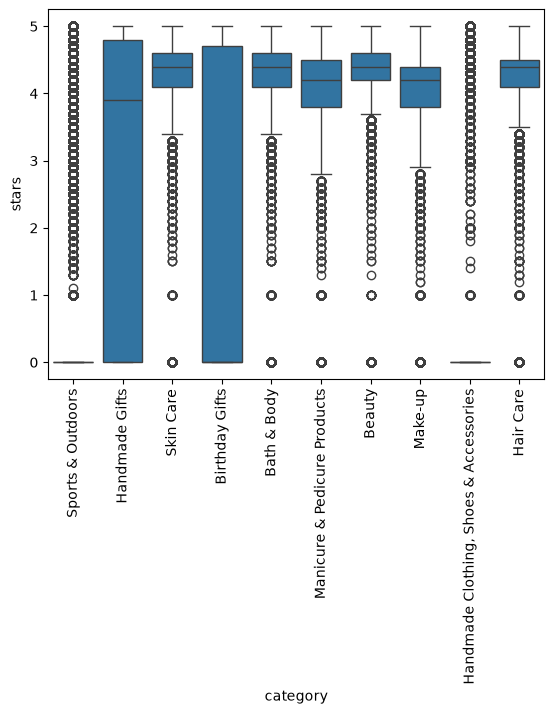

In [20]:
# Box Plots
sns.boxplot(data=df_clean[df_clean["category"].isin(top10)], x="category", y="stars")
plt.xticks(rotation=90)
plt.show()

In [21]:
df_clean.groupby("category")["stars"].median().sort_values(ascending=False).head()

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

'Computer Memory' is the category that tends to receive the highest median rating from customers.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?


In [26]:
# Correlation
correlation = df_clean['price'].corr(df_clean['stars'])
correlation

np.float64(-0.07767299878181323)

In [27]:
# Spearman correlation between 'price' and 'stars'
correlation = df_clean['price'].corr(df_clean['stars'], method='spearman')
correlation

np.float64(-0.06679697280768307)

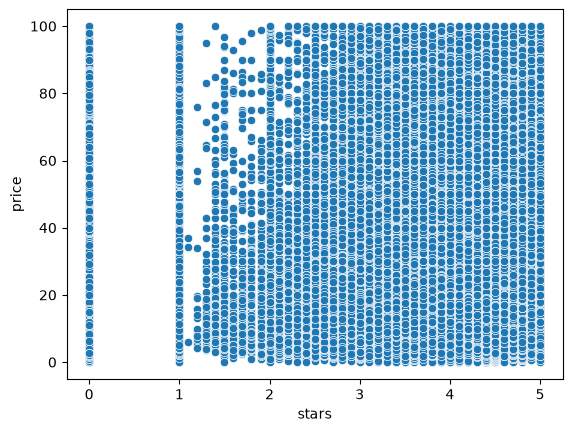

In [28]:
# Scatter plot
sns.scatterplot(data=df_clean, x='stars', y='price');

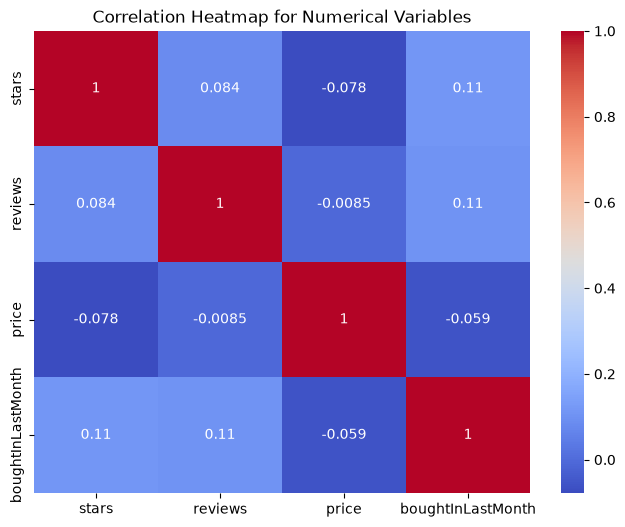

In [29]:
# Correlation heatmap for all numerical variables
df_numerical = df_clean.select_dtypes("number").drop(columns=["uid"])

correlation_matrix = df_numerical.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Numerical Variables")
plt.show()

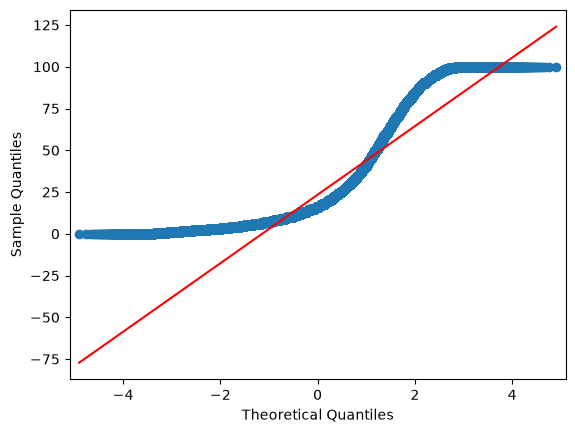

In [30]:
# Q-Q plot for 'price'
import statsmodels.api as sm

sm.qqplot(df_clean['price'], line='s');

Scatter plot: there’s no clear pattern. Products at every price get every rating, so price doesn’t predict rating (Spearman = −0.067). The column at 0 stars is the unrated products.

Correlation heatmap: all correlations are close to 0 (between −0.08 and 0.11), so no numerical variables are strongly related.

QQ plot: the points form an S-shape instead of following the line, so prices are not normally distributed. They flatten at £100 because the outliers were removed.